# 02-Anamorphose gaussienne (Normal Score)

## Objectif de ce notebook 

Transfomer les données brutes asymétriques du **Plomb (Pb)** en une distribution gaussienne centrée réduite (**Y.Pb**), nécessaire avant le
calcul du variogramme et le krigeage.

## Pourquoi cette transformation ?

Les données de Pb présentent une distribution **asymétrique** avec des valeurs extrêmes qui peuvent **biaiser** le variogramme et le krigeage. Le Normal Score corrige ce problème pour obtenir :
- Moyenne ≈ 0
- Variance ≈ 1
- Distribution gaussienne symétrique

## Contenu

1. Création de la base de données gstlearn
2. Filtrage des valeurs aberrantes 
3. Anamorphose empirique (Normal Score)
4. Anamorphose gaussienne par polynômes d'Hermite
5. Transformation Pb en Y.Pb
6. Vérification par variogramme dans l'espace gaussien
7. Back-transformation Y.Pb en Pb (contrôle qualité)

## Entrée / Sortie

- **Entrée** : `data/juradata.csv`
- **Sortie** : objet `db` (base gstlearn) contenant la variable transformée **Y.Pb**, réutilisé dans le notebook **03_variogramme_modelisation.ipynb**

In [ ]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gstlearn as gl
import gstlearn.plot as gp

# Ajout du chemin d'importation pour le module geostat_utils (remonte de jura/ jusqu'à src/)
sys.path.append(os.path.abspath(os.path.join("..", "..")))
import geostat_utils as gutils

# ---- Rechargement des données ----
data_jura = gutils.charger_donnees_jura()


## 1. Création de la base de données gstlearn

Les coordonnées spatiales (**X**, **Y**) et la variable étudiée (**Pb**) sont extraites du DataFrame **pandas** et converties en tableau **NumPy**, car **gstlearn** ne lit pas directement les DataFrames pandas.

In [ ]:
# ---- Création de la base de données gstlearn ---- 
db = gutils.creer_db_gstlearn(data_jura)
print(db)


## 2. Filtrage des valeurs aberrantes

Nous décidons de masquer les valeurs aberrantes du Plomb (Pb) en créantune **sélection** sur la base de données. Les échantillons dont la
concentration en Pb dépasse **132 mg/kg** sont exclus des analyses suivantes.

In [ ]:
# ---- Filtrage des valeurs aberrantes ----

gutils.filtrer_valeurs_aberrantes(db, "Pb", 132)
ax = gp.histogram(db, name="Pb", bins=30, color='salmon')
ax.decoration(title="Histogramme du Plomb (Pb) après filtrage des valeurs aberrantes")
plt.xlabel("Concentration en Pb (mg/kg)")
plt.ylabel("Nombre d'échantillons")
plt.show()
# ---- Statistiques après filtrage ----
stat_db_plomb = gl.DbStringFormat.createFromFlags(
    flag_vars=True, flag_stats=True, names=["*Pb"]
)
db.display(stat_db_plomb)


### 2-1 Visualisation spatiale après filtrage

La carte ci-dessous représente la distribution spatiale du **Plomb (Pb)** après filtrage des valeurs aberrantes.

**Observations :**

- Les **250 échantillons actifs** sont affichés après masquage des 9 valeurs aberrantes (> 132.04 mg/kg)
- Les valeurs aberrantes concentrées dans la zone **Sud-Ouest** (X ≈ 1, Y ≈ 1.5) ne sont plus visibles

In [ ]:
# ---- Visualisation spatiale après filtrage ----
ax = gp.plot(db, nameColor="Pb", s=30, cmap ="viridis")
gp.decoration(title="Carte de répartition spatiale \n des concentrations en Plomb (Pb)- données filtrées")
plt.xlabel("X (km)")
plt.ylabel("Y (km)")
plt.show()

## 3. Anamorphose empirique (Normal Score)

La transformation **Normal Score** convertit les données de Pb en distribution gaussienne en comparant les fonctions de distribution cumulées.

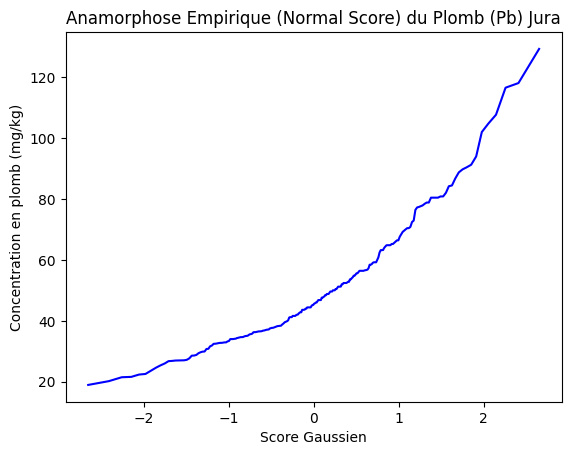

In [5]:
#---- Anamorphose Empirique (Normal Score) ----
anamorphose_empirique = gl.AnamEmpirical()
err = anamorphose_empirique.fitFromLocator(db)  
ax = gp.XY(anamorphose_empirique.getYDisc(), anamorphose_empirique.getZDisc())
plt.title("Anamorphose Empirique (Normal Score) du Plomb (Pb) Jura")
plt.xlabel("Score Gaussien")
plt.ylabel("Concentration en plomb (mg/kg)")
plt.show()

### 3.1 Histogramme de Y.Pb après transformation Normal Score

La variable **Pb** est transformée en **Y.Pb** grâce à l'anamorphose empirique. L'histogramme permet de vérifier que la distribution
obtenue se rapproche bien d'une forme gaussienne (en cloche). Cette colonne est ensuite supprimée, car la transformation définitive sera
réalisée plus loin avec l'anamorphose par polynômes d'Hermite.

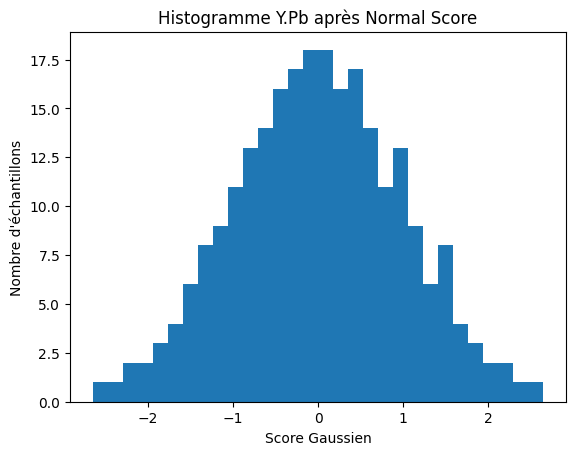

In [6]:
#---- Transformation Pb en Y.Pb (Normal Score) ----
err = anamorphose_empirique.rawToGaussian(db, "Pb")
ax = gp.histogram(db, name="Y.Pb", bins=30)
plt.title("Histogramme Y.Pb après Normal Score")
plt.xlabel("Score Gaussien")
plt.ylabel("Nombre d'échantillons")
plt.show()
db.deleteColumn("Y.Pb")
db.setLocator("Pb", gl.ELoc.Z)

## 4. Anamorphose gaussienne (polynômes d'Hermite)
L'anamorphose gaussienne est une méthode plus précise que l'anamorphose empirique. Elle approxime la transformation entre les valeurs brutes de
**Pb** et leur équivalent gaussien à l'aide d'une **somme de polynômes d'Hermite**.

**Choix du nombre de polynômes :** nous utilisons **25 polynômes**, un nombre courant dans ce type d'analyse, offrant un bon compromis entre précision et stabilité numérique.


Hermitian Anamorphosis
----------------------
Minimum absolute value for Y  = -3
Maximum absolute value for Y  = 2.9
Minimum absolute value for Z  = 19.4195
Maximum absolute value for Z  = 130.446
Minimum practical value for Y = -3
Maximum practical value for Y = 2.9
Minimum practical value for Z = 19.4195
Maximum practical value for Z = 130.446
Mean                          = 49.6875
Variance                      = 356.003
Number of Hermite polynomials = 25
Normalized coefficients for Hermite polynomials (punctual variable)
                 [,  0]     [,  1]     [,  2]     [,  3]     [,  4]     [,  5]     [,  6]
      [  0,]     49.688    -18.064      5.275     -0.512     -0.877      0.725     -0.026
      [  7,]     -0.052     -0.002     -0.241      0.157      0.235     -0.226     -0.119
      [ 14,]      0.196      0.005     -0.111      0.061      0.011     -0.078      0.076
      [ 21,]      0.060     -0.139     -0.022      0.175


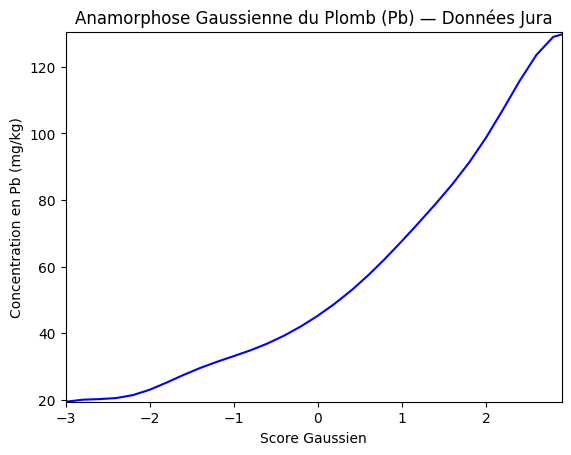

In [7]:
# ---- Anamorphose gaussienne (polynômes d'Hermite) ----
# La transformation est approximée par une somme de polynômes d'Hermite.
# avec un maximum raisonnable de 25.
anam_hermite = gl.AnamHermite(25)
anam_hermite.fitFromLocator(db)
anam_hermite.display()
ax = gp.anam(anam_hermite)
plt.title("Anamorphose Gaussienne du Plomb (Pb) — Données Jura")
plt.xlabel("Score Gaussien")
plt.ylabel("Concentration en Pb (mg/kg)")
plt.show()

## 4.1 Transformation Pb en Y.Pb

Après ajustement de l'anamorphose gaussienne, on transforme la variable brute **Pb** en sa transformée gaussienne **Y.Pb** et on affiche l'histogramme correspondant.


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 6
Total number of samples      = 259
Number of active samples     = 250

Data Base Statistics
--------------------
4 - Name Pb - Locator NA
 Nb of data          =         259
 Nb of active values =         250
 Minimum value       =      18.960
 Maximum value       =     129.200
 Mean value          =      49.688
 Standard Deviation  =      18.890
 Variance            =     356.835
6 - Name Y.Pb - Locator z1
 Nb of data          =         259
 Nb of active values =         250
 Minimum value       =      -3.000
 Maximum value       =       2.809
 Mean value          =       0.000
 Standard Deviation  =       0.998
 Variance            =       0.995

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = X - Locator = x1
Column = 2 - Name = Y - Locator = x2
Column = 3 - Name = Pb - Locator =

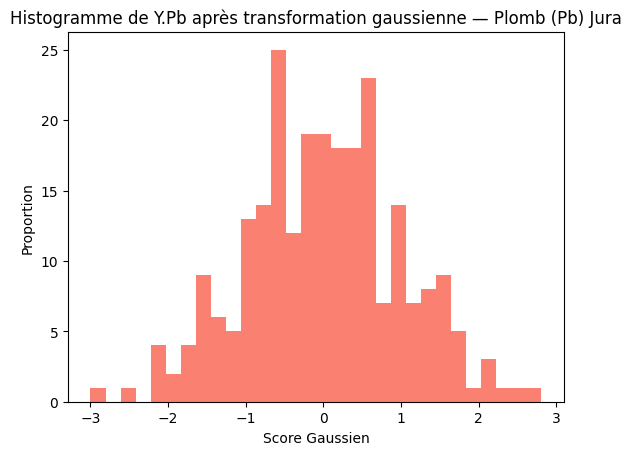

In [8]:
#---- Transformation Pb en Y.Pb ----
err = anam_hermite.rawToGaussianByLocator(db)
db.display(stat_db_plomb)
#---- Histogramme de Y.Pb ----
ax = gp.histogram(db, name="Y.Pb", bins=30, color='salmon')
plt.title("Histogramme de Y.Pb après transformation gaussienne — Plomb (Pb) Jura")
plt.xlabel("Score Gaussien")
plt.ylabel("Proportion")
plt.show()

## 4.2 Variogramme dans l'espace gaussien (Y.Pb)

Le variogramme est calculé dans l'espace gaussien après transformation **Normal Score** pour vérifier la stabilité de la structure spatiale du **Plomb (Pb)** transformé, avant le calcul détaillé du variogramme dans le notebook suivant.

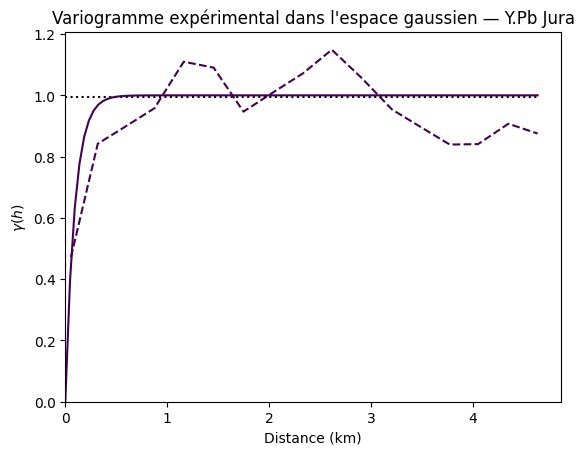

In [9]:
#---- Variogramme dans l'espace gaussien (Y.Pb) ----
vario_param_gauss = gl.VarioParam()
mydir = gl.DirParam.create(nlag=17, dlag=0.291066)
vario_param_gauss.addDir(mydir)
vario_gauss = gl.Vario(vario_param_gauss)
err = vario_gauss.compute(db)
model_gauss = gl.Model.createFromDb(db)
constr = gl.Constraints(1)
err = model_gauss.fit(vario_gauss, [gl.ECov.EXPONENTIAL], constr)
ax = gp.varmod(vario_gauss, model_gauss, showPairs= False)
plt.title("Variogramme expérimental dans l'espace gaussien — Y.Pb Jura")
plt.xlabel("Distance (km)")
plt.ylabel(r"$\gamma(h)$")
plt.show()

## 4.5 Back-transformation Y.Pb en Pb
La back-transformation permet de revenir à l'espace brut et de vérifier la qualité de l'anamorphose en comparant le **Pb original** avec les
**données reconstruites** (**Z.Y.Pb**). Si les points du nuage de corrélation sont proches d'une droite à 45°, cela confirme que la transformation  **Pb >> Y.Pb >> Pb** conserve bien l'information, et donc que l'anamorphose par polynômes d'Hermite est fiable pour la suite des
analyses (variogramme, krigeage).


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 7
Total number of samples      = 259
Number of active samples     = 250

Data Base Statistics
--------------------
4 - Name Pb - Locator NA
 Nb of data          =         259
 Nb of active values =         250
 Minimum value       =      18.960
 Maximum value       =     129.200
 Mean value          =      49.688
 Standard Deviation  =      18.890
 Variance            =     356.835
6 - Name Y.Pb - Locator NA
 Nb of data          =         259
 Nb of active values =         250
 Minimum value       =      -3.000
 Maximum value       =       2.809
 Mean value          =       0.000
 Standard Deviation  =       0.998
 Variance            =       0.995
7 - Name Z.Y.Pb - Locator z1
 Nb of data          =         259
 Nb of active values =         250
 Minimum value       =      19.420
 Maximum value       =     129.200


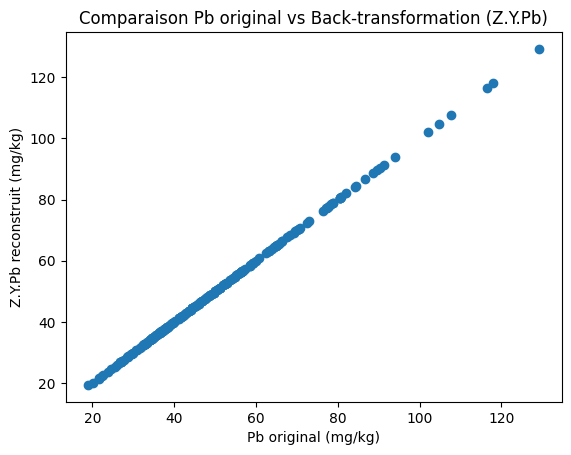

In [10]:
# ---- Back-transformation Y.Pb en Z.Y.Pb ----
anam_hermite.gaussianToRaw(db, "Y.Pb")
db.display(stat_db_plomb)

# ---- Comparaison Pb original vs données générées ----
ax = gp.correlation(db, namex="Pb", namey="Z.Y.Pb", asPoint=True)
plt.title("Comparaison Pb original vs Back-transformation (Z.Y.Pb)")
plt.xlabel("Pb original (mg/kg)")
plt.ylabel("Z.Y.Pb reconstruit (mg/kg)")
plt.show()
db.setLocator("Y.Pb", gl.ELoc.Z)

## Conclusion

La transformation Normal Score (anamorphose gaussienne par polynômes d'Hermite) a été appliquée avec succès sur le Plomb (Pb), après filtrage des 9 valeurs aberrantes. 

La variable **Y.Pb** obtenue (moyenne ≈ 0, variance ≈ 1) est utilisée pour la suite des analyses géostatistiques.

L'objet `db` (avec la variable Y.Pb) et l'objet `anam_hermite` sont réutilisés dans le notebook suivant **03_variogramme_modelisation.ipynb**.